In [129]:
%pip install wfdb numpy pandas matplotlib scikit-learn torch

Note: you may need to restart the kernel to use updated packages.


In [130]:
from pathlib import Path
import wfdb
import numpy as np
import matplotlib.pyplot as plt
import torch

In [131]:
#DATA_DIR = Path("data/mitdb")
#DATA_DIR.mkdir(parents=True, exist_ok=True)

In [132]:
DATA_DIR = Path("data/mitdb")

In [133]:
#wfdb.dl_database("mitdb", dl_dir=str(DATA_DIR))

In [134]:
print("Dataset exists:", (DATA_DIR / "100.hea").exists())

Dataset exists: True


In [135]:
record = wfdb.rdrecord(str(DATA_DIR / "100"))
annotation = wfdb.rdann(str(DATA_DIR / "100"), "atr")

In [136]:
signal = record.p_signal[:, 0]
sampling_rate = record.fs

In [137]:
print("Sampling rate:", sampling_rate)
print("Signal shape:", signal.shape)
print("Annotations loaded:", len(annotation.symbol))
print("Available annotation symbols:", sorted(set(annotation.symbol)))

Sampling rate: 360
Signal shape: (650000,)
Annotations loaded: 2274
Available annotation symbols: ['+', 'A', 'N', 'V']


In [138]:
time = np.arange(len(signal)) / sampling_rate

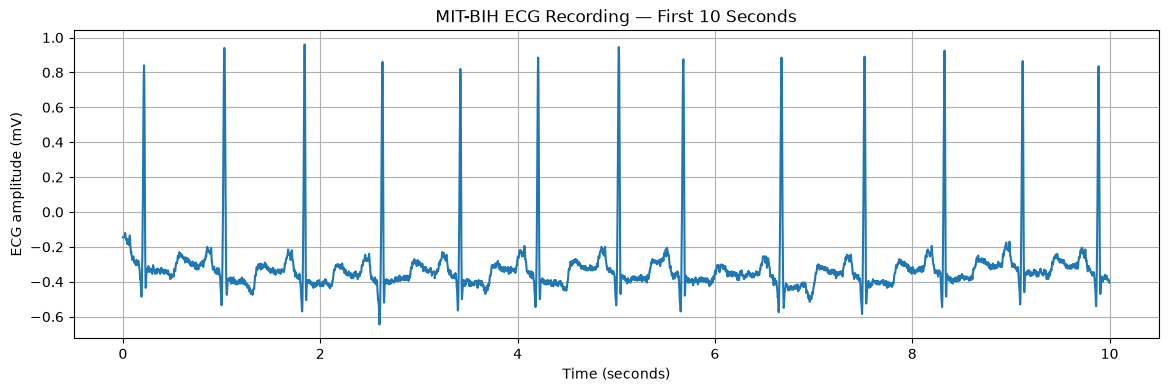

In [139]:
plt.figure(figsize=(14, 4))
plt.plot(time[:sampling_rate * 10], signal[:sampling_rate * 10])
plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude (mV)")
plt.title("MIT-BIH ECG Recording — First 10 Seconds")
plt.grid(True)
plt.show()

In [140]:
from sklearn.model_selection import GroupShuffleSplit

In [141]:
RECORDS = [
    "100", "101", "102", "103", "104", "105", "106", "107",
    "108", "109", "111", "112", "113", "114", "115", "116",
    "117", "118", "119", "121", "122", "123", "124", "200",
    "201", "202", "203", "205", "207", "208", "209", "210",
    "212", "213", "214", "215", "217", "219", "220", "221",
    "222", "223", "228", "230", "231", "232", "233", "234"
]

In [142]:
# Binary beat labels for this project:
# 0 = normal beat; 1 = selected abnormal beat types.
# Paced beats (/) and fusion-of-paced-and-normal beats (f), as well as
# unclassifiable beats (Q), are deliberately excluded rather than labeled abnormal.

In [143]:
NORMAL_SYMBOLS = {"N", "L", "R", "e", "j"}
ABNORMAL_SYMBOLS = {"A", "a", "J", "S", "V", "E", "F"}

In [144]:
print("Normal annotation symbols:", sorted(NORMAL_SYMBOLS))
print("Abnormal annotation symbols:", sorted(ABNORMAL_SYMBOLS))
print("Excluded annotation symbols include: /, f, Q, +, ~, |, and other unsupported symbols")

Normal annotation symbols: ['L', 'N', 'R', 'e', 'j']
Abnormal annotation symbols: ['A', 'E', 'F', 'J', 'S', 'V', 'a']
Excluded annotation symbols include: /, f, Q, +, ~, |, and other unsupported symbols


In [145]:
PRE_SAMPLES = int(0.2 * 360)
POST_SAMPLES = int(0.4 * 360)
INPUT_LENGTH = PRE_SAMPLES + POST_SAMPLES

In [146]:

def extract_beats(record_name):
    """Extract fixed-length ECG beats and binary labels from one MIT-BIH record.

    Labels:
        0 = Normal (N/L/R/e/j)
        1 = Abnormal (A/a/J/S/V/E/F)

    Unsupported annotation symbols are ignored.
    """
    record_path = str(DATA_DIR / record_name)

    record = wfdb.rdrecord(record_path)
    annotation = wfdb.rdann(record_path, "atr")

    signal = record.p_signal[:, 0]
    fs = record.fs

    # Verify the sampling rate before extracting beats.
    if fs != 360:
        raise ValueError(
            f"Record {record_name} has sampling rate {fs} Hz; "
            "expected 360 Hz."
        )

    # Extract 0.2 seconds before and 0.4 seconds after each annotation.
    pre = int(0.2 * fs)
    post = int(0.4 * fs)

    beats = []
    labels = []

    for sample, symbol in zip(annotation.sample, annotation.symbol):

        if symbol in NORMAL_SYMBOLS:
            label = 0
        elif symbol in ABNORMAL_SYMBOLS:
            label = 1
        else:
            continue  # Ignore unsupported annotation symbols.

        start = sample - pre
        end = sample + post

        # Skip beats that cross the signal boundaries.
        if start < 0 or end > len(signal):
            continue

        beat = signal[start:end].astype(np.float32)

        # Normalize each beat.
        beat = (beat - beat.mean()) / (beat.std() + 1e-8)

        beats.append(beat)
        labels.append(label)

    return beats, labels


In [147]:
from collections import Counter

In [148]:
record_name = "100"
record_path = str(DATA_DIR / record_name)
record = wfdb.rdrecord(record_path)
annotation = wfdb.rdann(record_path, "atr")

In [149]:
symbol_counts = Counter(annotation.symbol)
print(f"Annotation symbol counts for record {record_name}:")
for symbol, count in sorted(symbol_counts.items()):
    print(f"  {symbol!r}: {count}")

Annotation symbol counts for record 100:
  '+': 1
  'A': 33
  'N': 2239
  'V': 1


In [150]:
recognized_count = sum(
    symbol in NORMAL_SYMBOLS or symbol in ABNORMAL_SYMBOLS
    for symbol in annotation.symbol
)
beats, labels = extract_beats(record_name)

In [151]:
print("\nRecognized annotations before boundary filtering:", recognized_count)
print("Beats retained after boundary filtering:", len(labels))
print("Normal beats retained (label 0):", labels.count(0))
print("Abnormal beats retained (label 1):", labels.count(1))
print("Recognized beats excluded by boundary filtering:", recognized_count - len(labels))
print("Unsupported annotation symbols are excluded, not counted as abnormal.")


Recognized annotations before boundary filtering: 2273
Beats retained after boundary filtering: 2272
Normal beats retained (label 0): 2238
Abnormal beats retained (label 1): 34
Recognized beats excluded by boundary filtering: 1
Unsupported annotation symbols are excluded, not counted as abnormal.


In [152]:
record_groups = [
    "201_202" if record in {"201", "202"} else record
    for record in RECORDS
]

In [153]:
indices = np.arange(len(RECORDS))

In [154]:
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

In [155]:
train_idx, remaining_idx = next(
    split1.split(indices, groups=record_groups)
)

In [156]:
remaining_records = [RECORDS[i] for i in remaining_idx]
remaining_groups = [record_groups[i] for i in remaining_idx]

In [157]:
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

In [158]:
val_rel, test_rel = next(
    split2.split(remaining_records, groups=remaining_groups)
)

In [159]:
train_records = [RECORDS[i] for i in train_idx]
val_records = [remaining_records[i] for i in val_rel]
test_records = [remaining_records[i] for i in test_rel]

In [160]:
print("Training records:", len(train_records))
print("Validation records:", len(val_records))
print("Testing records:", len(test_records))

Training records: 32
Validation records: 8
Testing records: 8


In [161]:
def build_dataset(record_list):
    """Build arrays from selected annotation types and report each record's labels."""
    X, y = [], []

    for record_name in record_list:
        beats, labels = extract_beats(record_name)
        X.extend(beats)
        y.extend(labels)

        normal_count = labels.count(0)
        abnormal_count = labels.count(1)
        print(
            f"{record_name} | Total retained beats: {len(labels)} "
            f"| Normal (0): {normal_count} "
            f"| Abnormal (1): {abnormal_count}"
        )

    if not X:
        raise ValueError(
            "No beats were extracted. Check DATA_DIR, the MIT-BIH files, and annotation symbols."
        )

    X_array = np.asarray(X, dtype=np.float32)
    y_array = np.asarray(y, dtype=np.int64)
    print("\nDataset shape:", X_array.shape)
    print("Overall label counts:", dict(zip(*np.unique(y_array, return_counts=True))))
    return X_array, y_array


In [162]:
print("DATA_DIR:", DATA_DIR)
print("Record 100 exists:", (DATA_DIR / "100.hea").exists())
print("Record 100 data exists:", (DATA_DIR / "100.dat").exists())
print("Record 100 annotations exist:", (DATA_DIR / "100.atr").exists())

DATA_DIR: data/mitdb
Record 100 exists: True
Record 100 data exists: True
Record 100 annotations exist: True


In [163]:
X_train, y_train = build_dataset(train_records)
X_val, y_val = build_dataset(val_records)
X_test, y_test = build_dataset(test_records)

100 | Total retained beats: 2272 | Normal (0): 2238 | Abnormal (1): 34
101 | Total retained beats: 1863 | Normal (0): 1860 | Abnormal (1): 3
102 | Total retained beats: 103 | Normal (0): 99 | Abnormal (1): 4
105 | Total retained beats: 2567 | Normal (0): 2526 | Abnormal (1): 41
107 | Total retained beats: 59 | Normal (0): 0 | Abnormal (1): 59
109 | Total retained beats: 2531 | Normal (0): 2491 | Abnormal (1): 40
111 | Total retained beats: 2124 | Normal (0): 2123 | Abnormal (1): 1
112 | Total retained beats: 2538 | Normal (0): 2536 | Abnormal (1): 2
114 | Total retained beats: 1879 | Normal (0): 1820 | Abnormal (1): 59
115 | Total retained beats: 1952 | Normal (0): 1952 | Abnormal (1): 0
116 | Total retained beats: 2411 | Normal (0): 2301 | Abnormal (1): 110
117 | Total retained beats: 1534 | Normal (0): 1533 | Abnormal (1): 1
118 | Total retained beats: 2277 | Normal (0): 2165 | Abnormal (1): 112
119 | Total retained beats: 1987 | Normal (0): 1543 | Abnormal (1): 444
122 | Total retai

In [164]:

import numpy as np
from collections import Counter

datasets = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Testing": (X_test, y_test),
}

for name, (X, y) in datasets.items():
    print(f"\n{name} dataset")
    print("Feature shape:", X.shape)
    print("Label shape:", y.shape)
    print("Class counts:", dict(Counter(y)))

    assert len(X) == len(y), f"{name}: mismatched lengths"
    assert X.ndim == 2, f"{name}: expected 2D features"
    assert X.shape[1] == INPUT_LENGTH, (
        f"{name}: incorrect input length"
    )
    assert np.isfinite(X).all(), (
        f"{name}: NaN or infinite values found"
    )
    assert set(np.unique(y)).issubset({0, 1}), (
        f"{name}: unexpected labels"
    )

print("\nDataset validation completed successfully!")



Training dataset
Feature shape: (69067, 216)
Label shape: (69067,)
Class counts: {0: 61157, 1: 7910}

Validation dataset
Feature shape: (16941, 216)
Label shape: (16941,)
Class counts: {0: 15593, 1: 1348}

Testing dataset
Feature shape: (15410, 216)
Label shape: (15410,)
Class counts: {0: 13850, 1: 1560}

Dataset validation completed successfully!


In [165]:
print("\nShapes:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Shapes:
Train: (69067, 216) (69067,)
Validation: (16941, 216) (16941,)
Test: (15410, 216) (15410,)


In [166]:
for record_name in ["100", "102", "107", "104", "217"]:
    record_path = str(DATA_DIR / record_name)
    ann = wfdb.rdann(record_path, "atr")
    counts = Counter(ann.symbol)
    recognized_normal = sum(count for symbol, count in counts.items() if symbol in NORMAL_SYMBOLS)
    recognized_abnormal = sum(count for symbol, count in counts.items() if symbol in ABNORMAL_SYMBOLS)
    ignored = sum(count for symbol, count in counts.items()
                  if symbol not in NORMAL_SYMBOLS and symbol not in ABNORMAL_SYMBOLS)
    print(f"Record {record_name}: normal-symbol annotations={recognized_normal}, "
          f"abnormal-symbol annotations={recognized_abnormal}, ignored annotations={ignored}")


Record 100: normal-symbol annotations=2239, abnormal-symbol annotations=34, ignored annotations=1
Record 102: normal-symbol annotations=99, abnormal-symbol annotations=4, ignored annotations=2089
Record 107: normal-symbol annotations=0, abnormal-symbol annotations=59, ignored annotations=2081
Record 104: normal-symbol annotations=163, abnormal-symbol annotations=2, ignored annotations=2146
Record 217: normal-symbol annotations=244, abnormal-symbol annotations=162, ignored annotations=1874


In [167]:
%pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [168]:
from torch.utils.data import TensorDataset, DataLoader

In [169]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [170]:
def make_loader(X, y, shuffle=False):
    X_tensor = torch.tensor(X).unsqueeze(1)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    dataset = TensorDataset(X_tensor, y_tensor)

    return DataLoader(
        dataset,
        batch_size=128,
        shuffle=shuffle
    )

In [171]:
train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

In [172]:
import torch.nn as nn

In [173]:

class ECG_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)


In [174]:
model = ECG_CNN().to(device)

In [175]:
print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters:

In [176]:
import copy

In [177]:
normal_count = max(int((y_train == 0).sum()), 1)
abnormal_count = max(int((y_train == 1).sum()), 1)

In [178]:
pos_weight = torch.tensor(
    [normal_count / abnormal_count],
    dtype=torch.float32,
    device=device
)

In [179]:
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0003,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [180]:
EPOCHS = 40
PATIENCE = 8

In [181]:
best_val_loss = float("inf")
best_state = None
patience_counter = 0

In [182]:
history = {"train_loss": [], "val_loss": []}

In [183]:
def evaluate_loss(loader):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_loss += loss.item() * len(y_batch)
            total_samples += len(y_batch)

    return total_loss / max(total_samples, 1)

In [184]:
for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()

        # Prevent unusually large gradients.
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        total_samples += len(y_batch)

    train_loss = total_loss / max(total_samples, 1)
    val_loss = evaluate_loss(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")

model.load_state_dict(best_state)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")


Epoch 01/40 | Train Loss: 0.7953 | Validation Loss: 0.8794 | LR: 0.000300
Epoch 02/40 | Train Loss: 0.5592 | Validation Loss: 0.9091 | LR: 0.000300
Epoch 03/40 | Train Loss: 0.4798 | Validation Loss: 0.9152 | LR: 0.000300
Epoch 04/40 | Train Loss: 0.4415 | Validation Loss: 0.9608 | LR: 0.000150
Epoch 05/40 | Train Loss: 0.4046 | Validation Loss: 1.0440 | LR: 0.000150
Epoch 06/40 | Train Loss: 0.3957 | Validation Loss: 1.0049 | LR: 0.000150
Epoch 07/40 | Train Loss: 0.3768 | Validation Loss: 0.9443 | LR: 0.000075
Epoch 08/40 | Train Loss: 0.3682 | Validation Loss: 0.9913 | LR: 0.000075
Epoch 09/40 | Train Loss: 0.3591 | Validation Loss: 1.0280 | LR: 0.000075
Early stopping.

Best epoch: 1
Best validation loss: 0.8794


In [185]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import torch

model.eval()

val_probabilities = []

with torch.no_grad():
    for X_batch, _ in val_loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        probabilities = torch.sigmoid(logits)

        val_probabilities.extend(
            probabilities.cpu().numpy()
        )

val_probabilities = np.asarray(val_probabilities)

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-8)
)

best_index = np.argmax(f1_scores)
best_threshold = float(thresholds[best_index])

print(f"Selected threshold: {best_threshold:.4f}")
print(f"Validation precision: {precision[best_index]:.4f}")
print(f"Validation recall: {recall[best_index]:.4f}")
print(f"Validation F1-score: {f1_scores[best_index]:.4f}")


Selected threshold: 0.5770
Validation precision: 0.8833
Validation recall: 0.5504
Validation F1-score: 0.6782


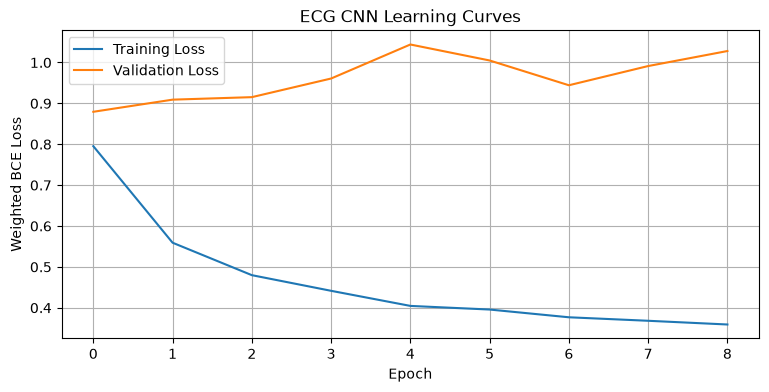

In [186]:
plt.figure(figsize=(9, 4))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Weighted BCE Loss")
plt.title("ECG CNN Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

In [187]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

model.eval()

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [188]:
all_probabilities = []
all_labels = []

In [189]:
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        probabilities = torch.sigmoid(logits)

        all_probabilities.extend(probabilities.cpu().numpy())
        all_labels.extend(y_batch.numpy())

In [190]:
y_true = np.asarray(all_labels, dtype=int)
y_prob = np.asarray(all_probabilities)
y_pred = (y_prob >= best_threshold).astype(int)

In [191]:
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.97      0.90      0.93     13850
    Abnormal       0.46      0.79      0.58      1560

    accuracy                           0.89     15410
   macro avg       0.72      0.84      0.76     15410
weighted avg       0.92      0.89      0.90     15410



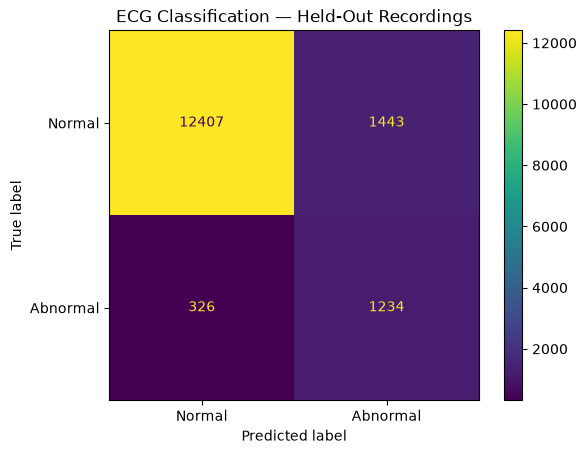

ROC-AUC: 0.9091287605294824


In [192]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Abnormal"]
).plot()

plt.title("ECG Classification — Held-Out Recordings")
plt.show()

if len(np.unique(y_true)) == 2:
    print("ROC-AUC:", roc_auc_score(y_true, y_prob))
else:
    print("ROC-AUC unavailable: test set contains only one class.")

In [193]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_length": INPUT_LENGTH,
        "sampling_rate": 360,
        "class_names": {
            0: "Normal",
            1: "Abnormal"
        },
        "threshold": float(best_threshold)
    },
    "cardiosignal_cnn.pth"
)

print("Model saved: cardiosignal_cnn.pth")
print(f"Saved threshold: {best_threshold:.4f}")

Model saved: cardiosignal_cnn.pth
Saved threshold: 0.5770
